# **Data Science Mini Project**  
**Student Name:** KATHAR MASTHAN A

**Batch:** DSB04

**Project Title:** Bank Term Deposit Prediction

**Submission Date:**

# 1. Problem Definition  

# 1.1 Business / Real-World Problem Statement

Banks face a major challenge in identifying which customers are most likely to respond positively to a term deposit offer before launching a telephone marketing campaign. Customer information is usually spread across different records, such as personal details, account and loan history, and the results of earlier campaigns, and it is rarely combined to guide who should be contacted. As a result, campaigns depend on broad, untargeted calling instead of informed selection. This leads to wasted staff effort, higher marketing costs, and repeated calls to uninterested customers, which weakens their trust in the bank.

# 1.2 Project Objectives

The goal of this project is to build a machine learning model that predicts whether a customer will subscribe to a term deposit, by combining demographic, financial and previous campaign data. This helps the bank focus its calls on high-potential customers and plan better campaigns.

# 1.3 Machine Learning Problem Type

Note:

 Supervised Learning –
Classification (Binary: yes / no)





# 2. Dataset Understanding
# 2.1 Dataset Source

Dataset Source: <font color='blue'>https://archive.ics.uci.edu/dataset/222/bank+marketing</font>

Citation: S. Moro, P. Rita, P. Cortez. (2014) “A data-driven approach to predict the success of bank telemarketing.” Decision Support Systems, vol. 62, pp. 22–31. DOI: 10.1016/j.dss.2014.03.001

# 2.2 Dataset Description


*  Number of rows: 4521
*   Number of columns: 17 (16 features + 1 target)


*   Dataset purpose: The dataset records the results of telephone marketing campaigns run by a bank to sell term deposits. Its purpose is to help the bank predict which customers are likely to subscribe, so that future campaigns can be targeted better and made more efficient.








## **2.3 Feature Description**
| Feature Name                                    | Data Type   | Description                                                                                     |
| ----------------------------------------------- | ----------- | ----------------------------------------------------------------------------------------------- |
| age                                  | Numeric | The age of the customer in years       |
| job                                | Categorical | The type of job the customer does (management, blue-collar, student, retired, etc.).                        |
| martial                               | Categorical     | The marital status of the customer (married, single, divorced).                              |
| education                                          | Categorical | The education level of the customer (primary, secondary, tertiary, unknown).                                |
| default                      | Categorical | Shows whether the customer has credit in default (yes/no).    |
| balance                          | Numeric | The average yearly balance in the customer’s account, in euros.        |
| housing                  | Categorical     | Shows whether the customer has a housing loan (yes/no).           |
| loan                                     | Categorical |  Shows whether the customer has a personal loan (yes/no).                                                           |
| contact                         | Categorical |    The type of communication used to contact the customer (cellular, telephone, unknown).                                |
| day                          | Numeric |  The day of the month on which the customer was last contacted.                                |
| month                              | Categorical |  The month of the year in which the customer was last contacted.                                 |
| duration                              | Numeric | The length of the last call with the customer, in seconds.                                   |
| campaign                                 | Numeric     |     The number of times the customer was contacted during this campaign.                      |
| pdays                                      | Numeric |The number of days since the customer was last contacted in a previous campaign (-1 means not contacted before).      |
| previous                       | Numeric | Binary indicator showing if the student requires educational special needs support.               |
| poutcome                                          | Categorical | The outcome of the previous marketing campaign (success, failure, other, unknown).                |
| y                        | Categorical |   Target: shows whether the customer subscribed to a term deposit (yes/no).                      |
|

# 2.4 Target Variable

Target Variable:


*   Name: y (renamed to deposit in the notebook)
*   Description: A categorical variable showing whether the customer subscribed to a term deposit or not. It has two values, yes and no.


*   Prediction Goal: To predict whether a customer will subscribe to a term deposit (yes) or not (no), based on their personal, financial and previous campaign details.






Name: y (renamed to deposit in the notebook)
Description: A categorical variable showing whether the customer subscribed to a term deposit or not. It has two values, yes and no.
Prediction Goal: To predict whether a customer will subscribe to a term deposit (yes) or not (no), based on their personal, financial and previous campaign details.

# 3. Exploratory Data Analysis (EDA)
# 3.1 Import Required Libraries

In [ ]:
# Install visualization packages
%pip install -q matplotlib seaborn

#Import data manipulation packages
import pandas as pd
import numpy as np

#Import visulaizaton packages
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# 3.2 Load Dataset

In [ ]:
df = pd.read_excel(r"C:\Users\katha\Downloads\bank.xlsx")

# 3.3 Dataset Overview

In [ ]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


In [ ]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


In [ ]:
df.describe(include='object')

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,4521,4521,4521,4521,4521,4521,4521,4521,4521,4521
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,yes,no,cellular,may,unknown,no
freq,969,2797,2306,4445,2559,3830,2896,1398,3705,4000


In [ ]:
print("Number of rows:",df.shape[0],sep="")
print("Number of columns:",df.shape[1],sep="")

Number of rows:4521
Number of columns:17


In [ ]:
print("Target Variable counts:")
print(df['y'].value_counts())

Target Variable counts:
y
no     4000
yes     521
Name: count, dtype: int64


# 3.4 Missing and Duplicate Value Analysis

In [ ]:
print("Missing values counts")
print(df.isna().sum())
print("\nDuplicate values count:",df.duplicated().sum())

Missing values counts
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Duplicate values count: 0


#3.5 Correlation Analysis

In [ ]:
num_cols=df.select_dtypes(include=np.number).columns
cat_cols=df.select_dtypes(include=['object']).columns

In [ ]:
num_cols

Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')

In [ ]:
cat_cols

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'y'],
      dtype='object')

In [ ]:
num_df=df[num_cols]
cat_df=df[cat_cols]

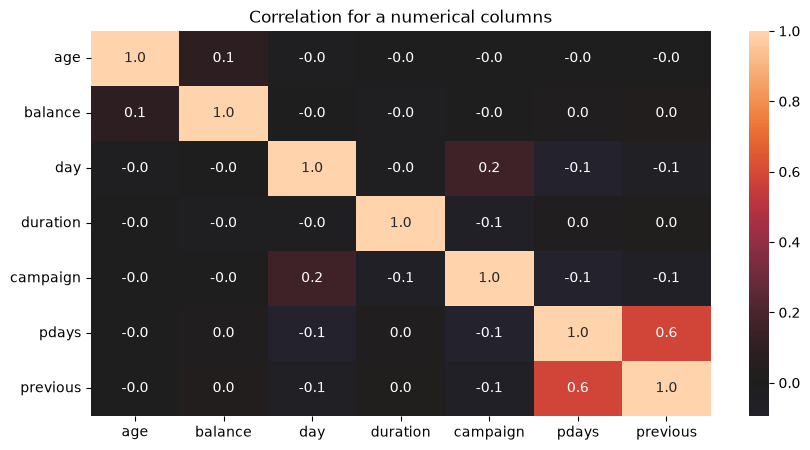

In [ ]:
num_corr=num_df.corr()
plt.figure(figsize=(10,5))
sns.heatmap(num_corr,annot=True,fmt=".1f",center=0)
plt.title("Correlation for a numerical columns")
plt.show()

In [ ]:
#Rename the target column
df_cp=df.copy()
df_cp.rename(columns={'y':'deposit'},inplace=True)
df_cp.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


#3.6 Data Visualization

# Pie Chart

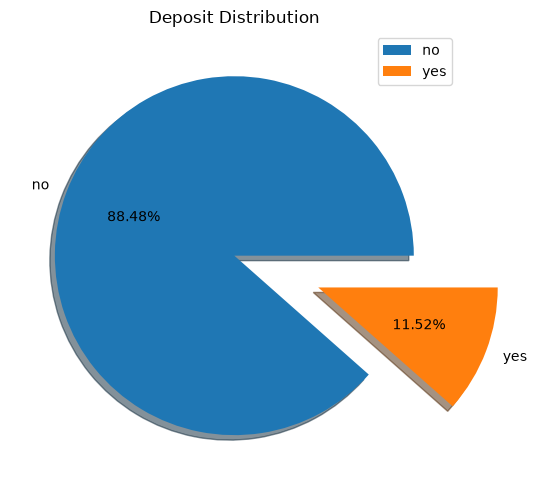

In [ ]:
deposit_count=df_cp['deposit'].value_counts()
plt.figure(figsize=(10,5))
plt.pie(deposit_count,labels=deposit_count.index,autopct="%1.2f%%",shadow=True,explode=[0,0.5])
plt.title("Deposit Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
yes=round(4521*11.5/100)
print(yes)
#Around 520 customers are want to get a term deposi of 4521

520


# Bar Plot

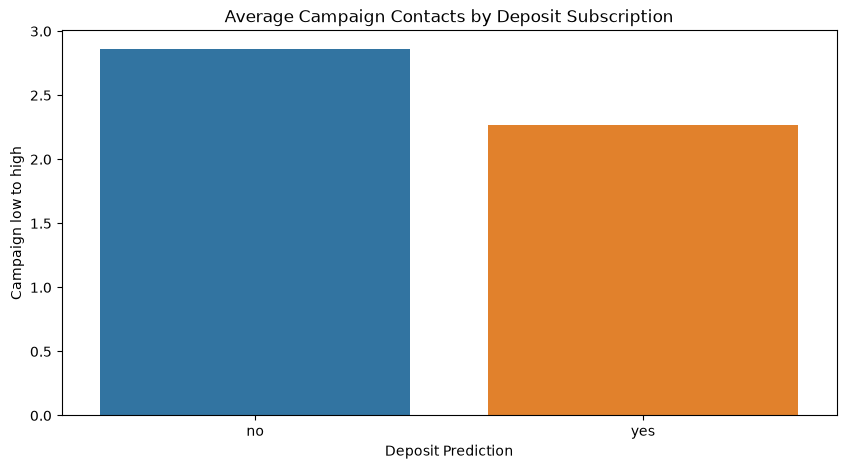

In [ ]:
plt.figure(figsize=(10,5))
sns.barplot(data=df_cp,
            x='deposit',
            y='campaign',
            hue='deposit',
            errorbar=None
            )
plt.title("Average Campaign Contacts by Deposit Subscription")
plt.xlabel("Deposit Prediction")
plt.ylabel("Campaign low to high")

plt.show()

# Count Plot

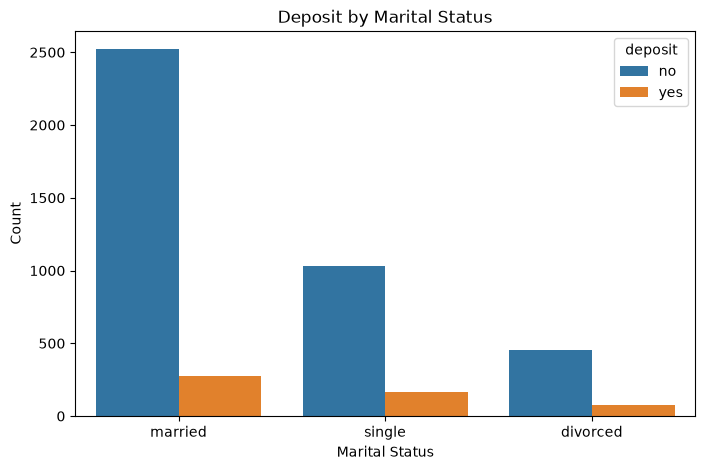

In [ ]:
#Shows how many customers from martial group are accepted
plt.figure(figsize=(8, 5))
sns.countplot(data=df_cp, x='marital', hue='deposit')
plt.title("Deposit by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Count")
plt.show()

# Bar plot

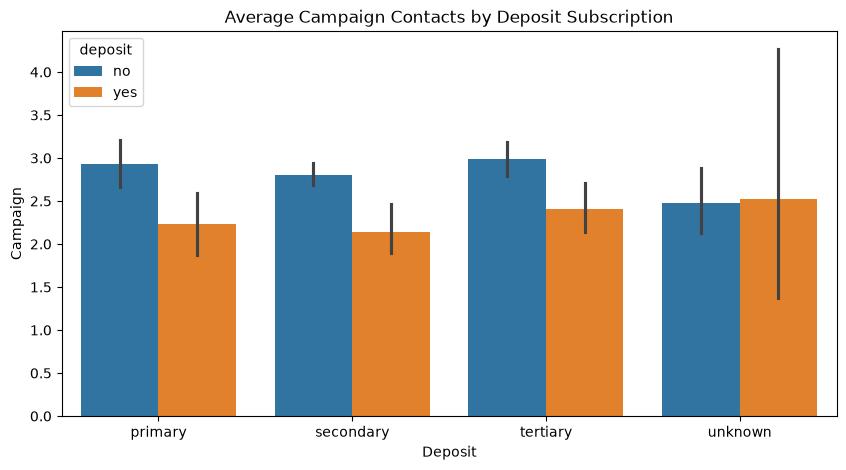

In [ ]:
#Show the education sectors with campaign conducted
plt.figure(figsize=(10,5))
sns.barplot(data=df_cp,
            x='education',
            y='campaign',
            hue='deposit',
            )
plt.title("Average Campaign Contacts by Deposit Subscription")
plt.xlabel("Deposit")
plt.ylabel("Campaign")

plt.show()


In [ ]:
df_cp['education'].value_counts()

education
secondary    2306
tertiary     1350
primary       678
unknown       187
Name: count, dtype: int64

# Histogram

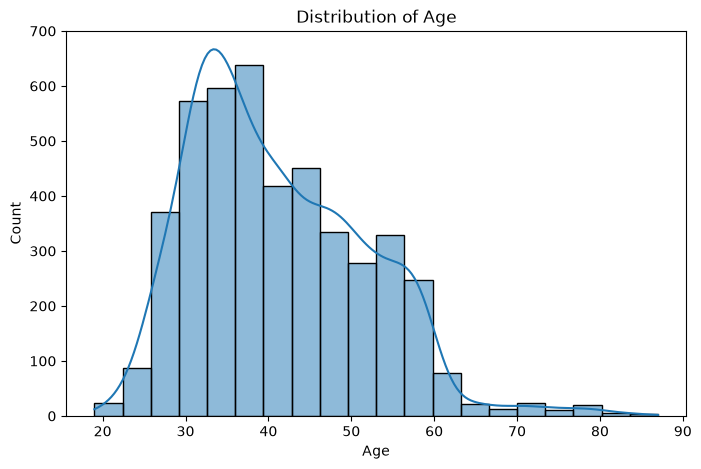

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_cp, x='age', bins=20, kde=True)
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.show()
#Most average age of customers are between 30 to 50

# Scatter Plot

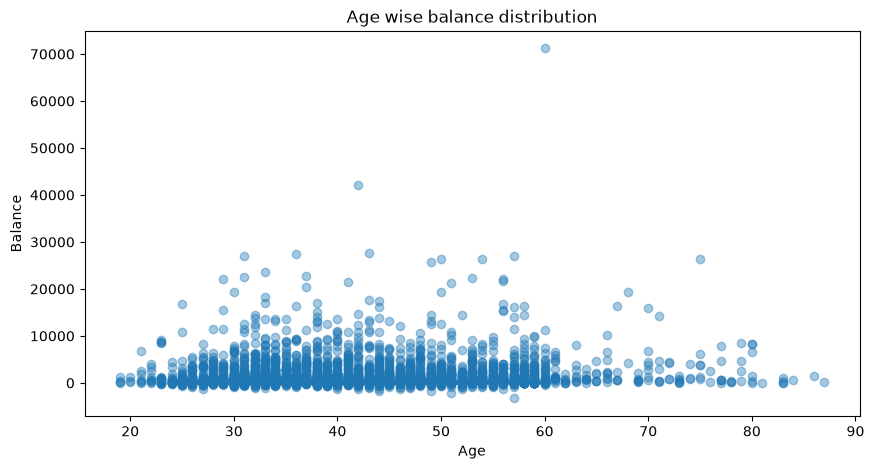

In [ ]:
#Most customers have low balance few have high balance

plt.figure(figsize=(10,5))
plt.scatter(df_cp['age'],df_cp['balance'],alpha=0.4)
plt.xlabel("Age")
plt.ylabel("Balance")
plt.title("Age wise balance distribution")
plt.show()


In [ ]:
#Max balance
df_cp['balance'].max()

np.int64(71188)

# Box Plot

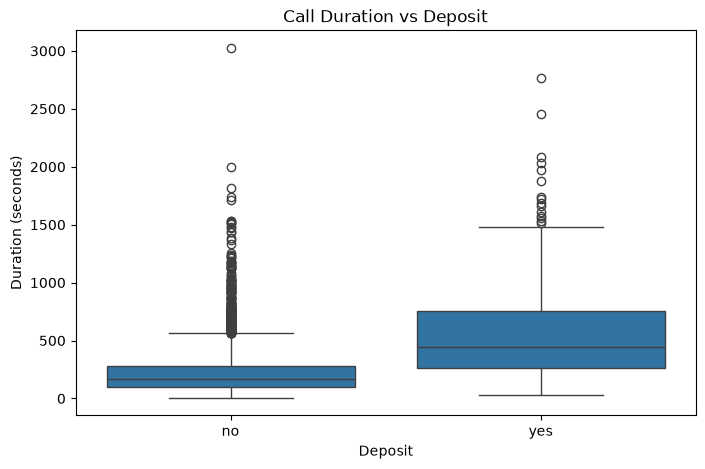

In [ ]:
#Customers who said yes usually had longer calls than those who said no
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_cp, x='deposit', y='duration')
plt.title("Call Duration vs Deposit")
plt.xlabel("Deposit")
plt.ylabel("Duration (seconds)")
plt.show()

#4. Data Preprocessing
#4.1 Missing Value Treatment

In [ ]:
df.isna().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

#4.2 Duplicate Value Handling

In [ ]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
4516    False
4517    False
4518    False
4519    False
4520    False
Length: 4521, dtype: bool

In [ ]:
df.duplicated().sum()

np.int64(0)

#4.3 Outlier Treatment

In [ ]:
num_col=df_cp.select_dtypes(include=np.number).columns
cat_col=df_cp.select_dtypes(include=['object']).columns

In [ ]:
print(f"Numerical columns:{[num_col]}")
print(f"\nCategorical columns:{[cat_col]}")

Numerical columns:[Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')]

Categorical columns:[Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'deposit'],
      dtype='object')]


In [ ]:
num_d=df_cp[num_col]
cat_d=df_cp[cat_col]

In [ ]:
num_d.head()

,age,balance,day,duration,campaign,pdays,previous
0,30,1787,19,79,1,-1,0
1,33,4789,11,220,1,339,4
2,35,1350,16,185,1,330,1
3,30,1476,3,199,4,-1,0
4,59,0,5,226,1,-1,0


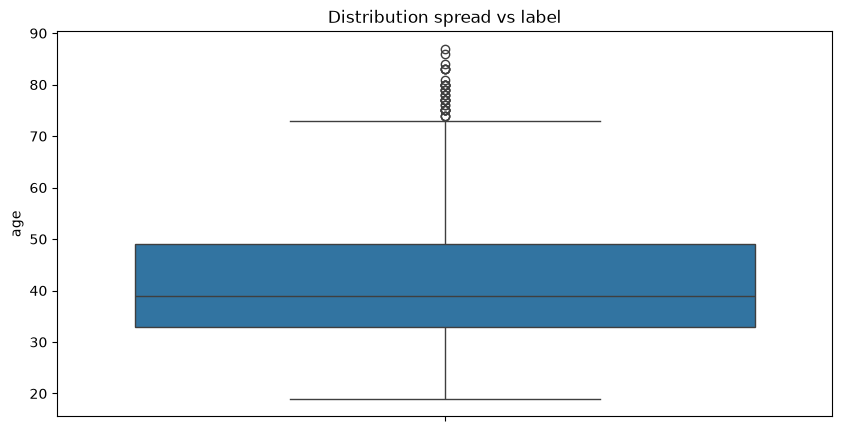

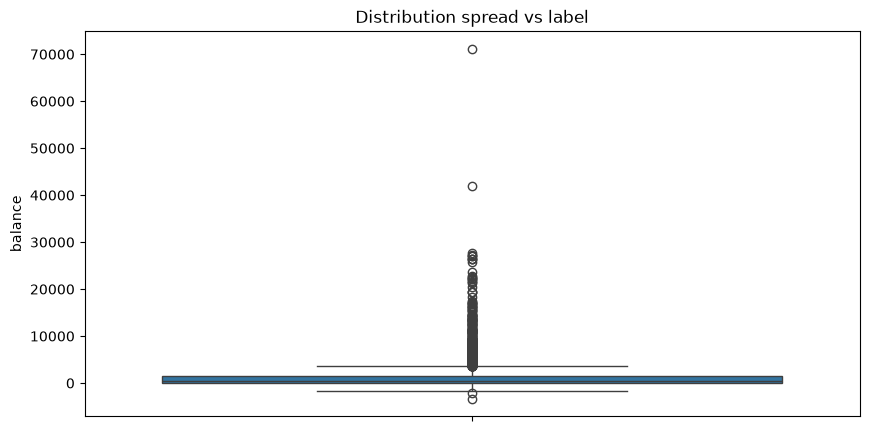

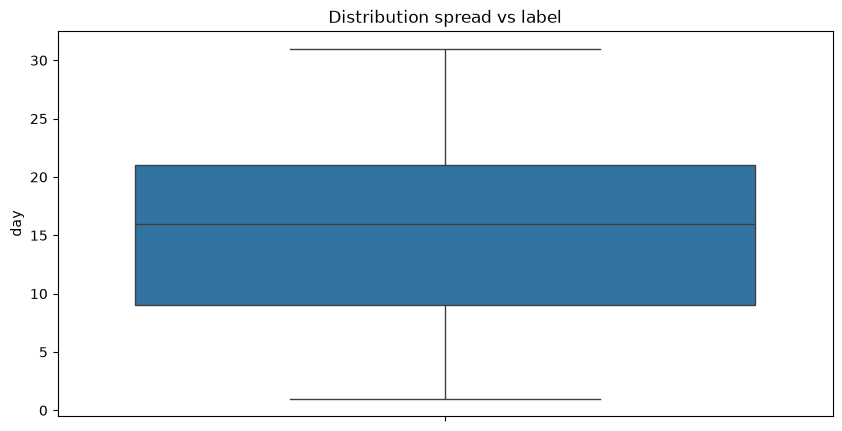

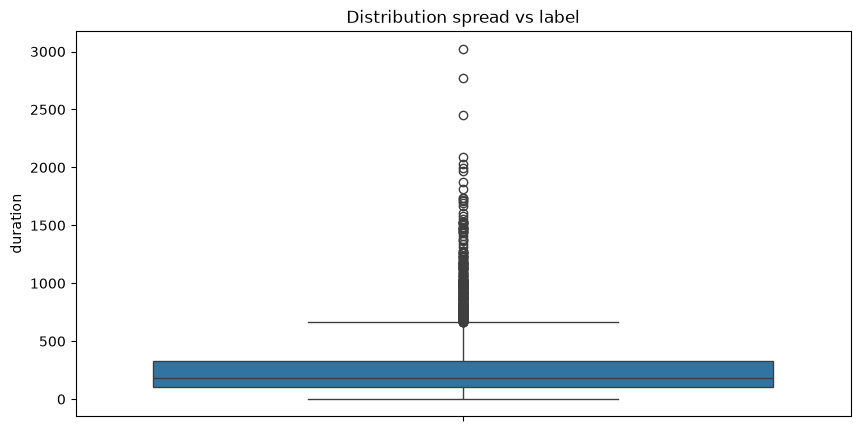

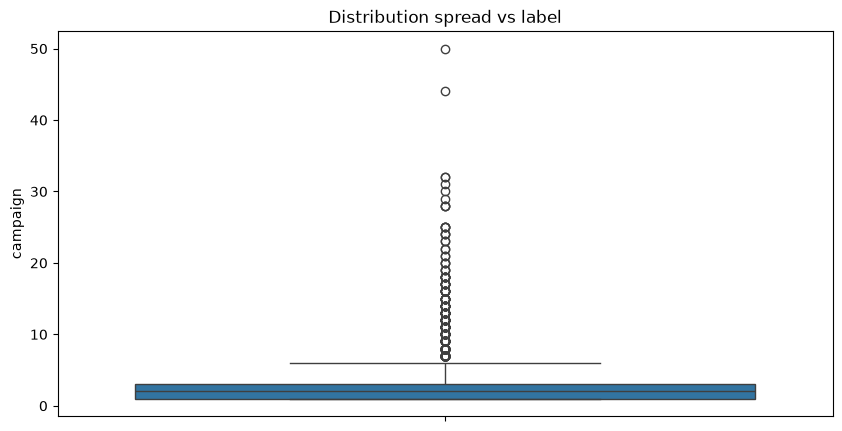

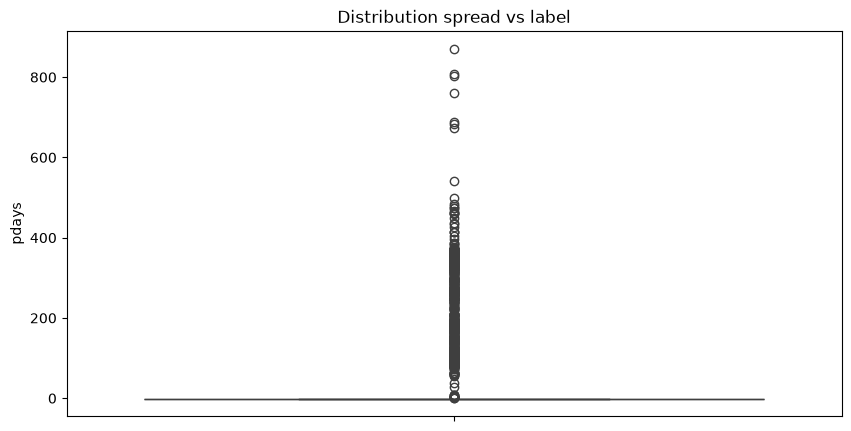

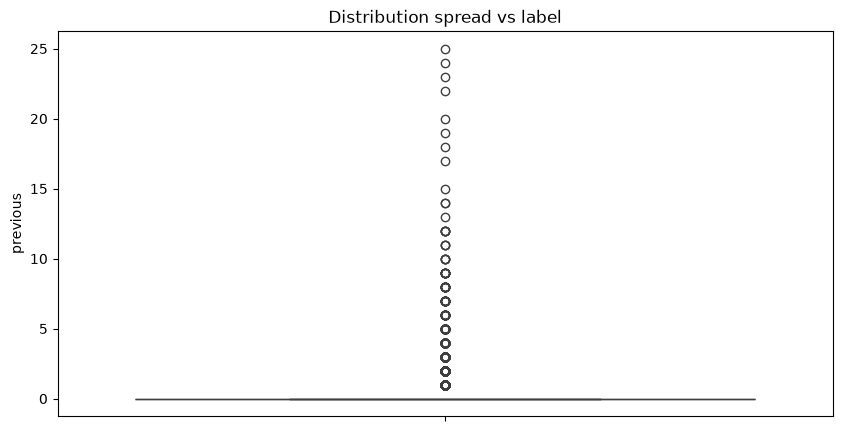

In [ ]:
for col in num_d:
  plt.figure(figsize=(10,5))
  sns.boxplot(data=df_cp,y=col)
  plt.title(f"Distribution spread vs label")
  plt.show()

#IQR Method

In [ ]:
for col in num_d:
  Q1=df_cp[col].quantile(0.25)
  Q3=df_cp[col].quantile(0.75)

  IQR=Q3-Q1

  lower_bound=Q1-1.5*IQR
  upper_bound=Q3+1.5*IQR

  lower_value=df_cp[col]<lower_bound
  upper_value=df_cp[col]>upper_bound

  print(f"Feature'{col}': Cap around {lower_value.sum()} and {upper_value.sum()}")
  print(f"Success Feature '{col}': Cap around {lower_bound} and {upper_bound}")

  df_cp[col]=np.clip(df_cp[col],lower_bound,upper_bound)



Feature'age': Cap around 0 and 38
Success Feature 'age': Cap around 9.0 and 73.0
Feature'balance': Cap around 2 and 504
Success Feature 'balance': Cap around -2047.5 and 3596.5
Feature'day': Cap around 0 and 0
Success Feature 'day': Cap around -9.0 and 39.0
Feature'duration': Cap around 0 and 330
Success Feature 'duration': Cap around -233.5 and 666.5
Feature'campaign': Cap around 0 and 318
Success Feature 'campaign': Cap around -2.0 and 6.0
Feature'pdays': Cap around 0 and 816
Success Feature 'pdays': Cap around -1.0 and -1.0
Feature'previous': Cap around 0 and 816
Success Feature 'previous': Cap around 0.0 and 0.0


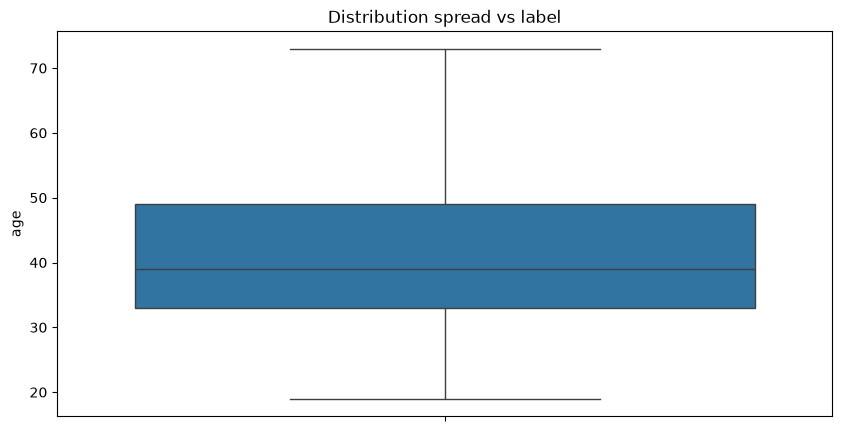

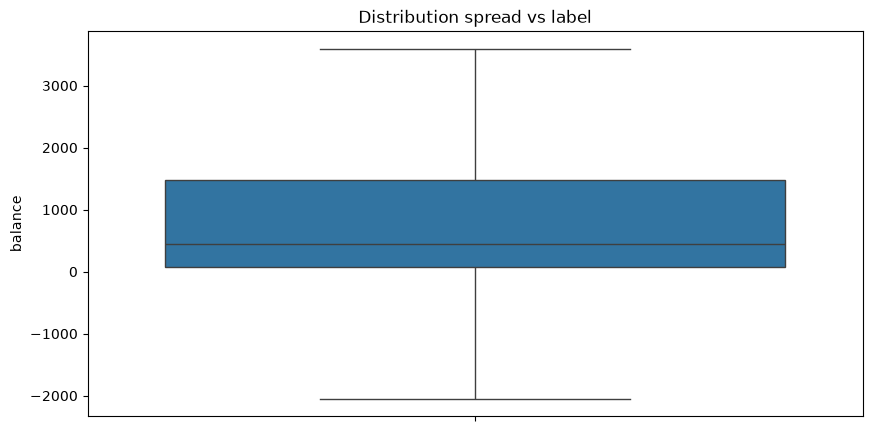

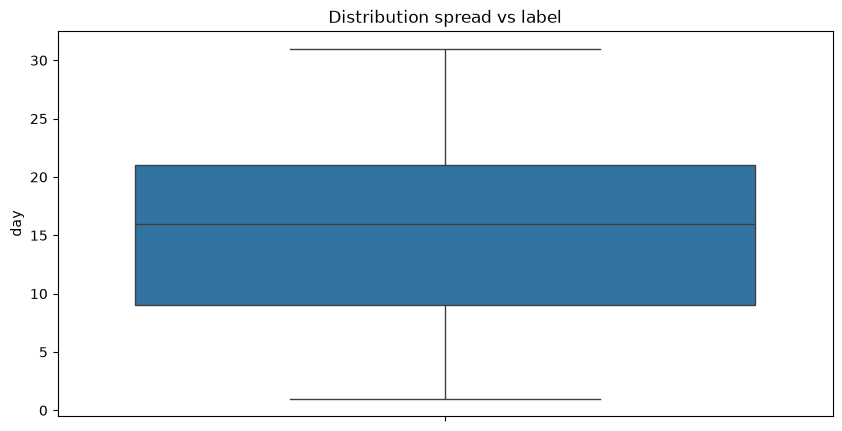

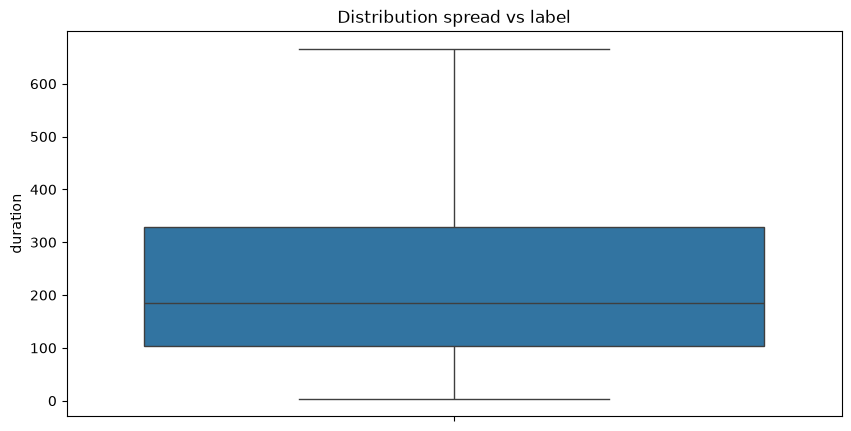

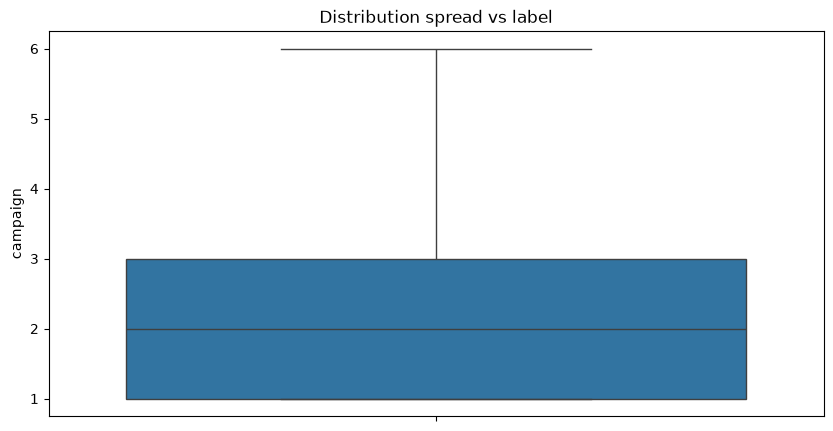

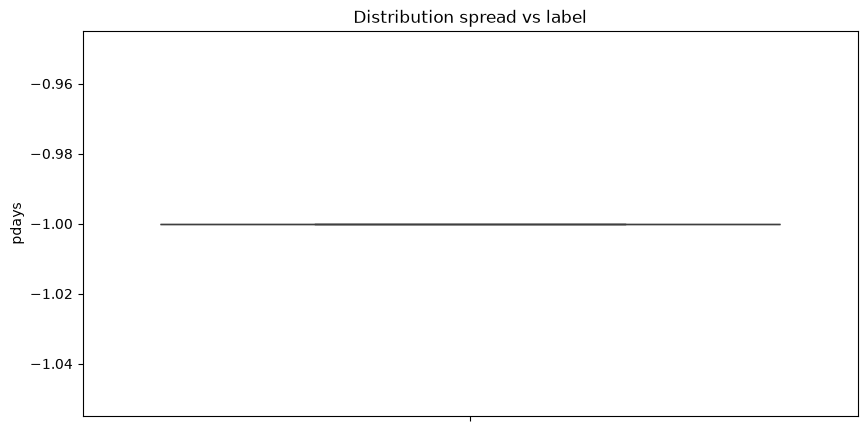

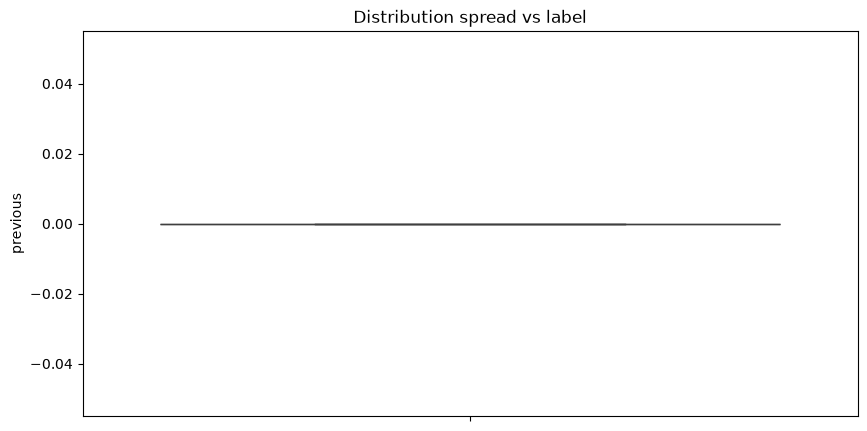

In [ ]:
for col in num_d:
  plt.figure(figsize=(10,5))
  sns.boxplot(data=df_cp,y=col)
  plt.title(f"Distribution spread vs label")
  plt.show()

#4.4 Encoding

In [ ]:
for col in cat_col:
  print(f'{col}:{df_cp[col].unique()}\n')

job:['unemployed' 'services' 'management' 'blue-collar' 'self-employed'
 'technician' 'entrepreneur' 'admin.' 'student' 'housemaid' 'retired'
 'unknown']

marital:['married' 'single' 'divorced']

education:['primary' 'secondary' 'tertiary' 'unknown']

default:['no' 'yes']

housing:['no' 'yes']

loan:['no' 'yes']

contact:['cellular' 'unknown' 'telephone']

month:['oct' 'may' 'apr' 'jun' 'feb' 'aug' 'jan' 'jul' 'nov' 'sep' 'mar' 'dec']

poutcome:['unknown' 'failure' 'other' 'success']

deposit:['no' 'yes']



In [ ]:
#One Hot Encoding for all categorical columns
df_encoded = pd.get_dummies(df_cp, columns=cat_col.drop('deposit'), drop_first=True, dtype=int)
df_encoded

,age,balance,day,duration,campaign,pdays,previous,deposit,job_blue-collar,job_entrepreneur,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,30,1787.0,19,79.0,1,-1,0,no,0,0,...,0,0,0,0,0,1,0,0,0,1
1,33,3596.5,11,220.0,1,-1,0,no,0,0,...,0,0,0,1,0,0,0,0,0,0
2,35,1350.0,16,185.0,1,-1,0,no,0,0,...,0,0,0,0,0,0,0,0,0,0
3,30,1476.0,3,199.0,4,-1,0,no,0,0,...,0,1,0,0,0,0,0,0,0,1
4,59,0.0,5,226.0,1,-1,0,no,1,0,...,0,0,0,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4516,33,-333.0,30,329.0,5,-1,0,no,0,0,...,1,0,0,0,0,0,0,0,0,1
4517,57,-2047.5,9,153.0,1,-1,0,no,0,0,...,0,0,0,1,0,0,0,0,0,1
4518,57,295.0,19,151.0,6,-1,0,no,0,0,...,0,0,0,0,0,0,0,0,0,1
4519,28,1137.0,6,129.0,4,-1,0,no,1,0,...,0,0,0,0,0,0,0,1,0,0


In [ ]:
print(df_cp.shape)
print(df_encoded.shape)


(4521, 17)
(4521, 43)


In [ ]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 43 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  4521 non-null   int64  
 1   balance              4521 non-null   float64
 2   day                  4521 non-null   int64  
 3   duration             4521 non-null   float64
 4   campaign             4521 non-null   int64  
 5   pdays                4521 non-null   int64  
 6   previous             4521 non-null   int64  
 7   deposit              4521 non-null   object 
 8   job_blue-collar      4521 non-null   int64  
 9   job_entrepreneur     4521 non-null   int64  
 10  job_housemaid        4521 non-null   int64  
 11  job_management       4521 non-null   int64  
 12  job_retired          4521 non-null   int64  
 13  job_self-employed    4521 non-null   int64  
 14  job_services         4521 non-null   int64  
 15  job_student          4521 non-null   i

In [ ]:
#LabelEncoder for a target column
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df_encoded['deposit']=le.fit_transform(df_encoded['deposit'])

In [ ]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 43 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  4521 non-null   int64  
 1   balance              4521 non-null   float64
 2   day                  4521 non-null   int64  
 3   duration             4521 non-null   float64
 4   campaign             4521 non-null   int64  
 5   pdays                4521 non-null   int64  
 6   previous             4521 non-null   int64  
 7   deposit              4521 non-null   int64  
 8   job_blue-collar      4521 non-null   int64  
 9   job_entrepreneur     4521 non-null   int64  
 10  job_housemaid        4521 non-null   int64  
 11  job_management       4521 non-null   int64  
 12  job_retired          4521 non-null   int64  
 13  job_self-employed    4521 non-null   int64  
 14  job_services         4521 non-null   int64  
 15  job_student          4521 non-null   i

#4.5 Feature Scaling

#Standard Scaler

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
df_encoded[num_col]=scaler.fit_transform(df_encoded[num_col])

In [ ]:
df_encoded.head()

,age,balance,day,duration,campaign,pdays,previous,deposit,job_blue-collar,job_entrepreneur,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,-1.067914,0.655937,0.374052,-0.878134,-0.871205,0.0,0.0,0,0,0,...,0,0,0,0,0,1,0,0,0,1
1,-0.779891,2.114953,-0.596026,-0.117521,-0.871205,0.0,0.0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,-0.587875,0.303580,0.010273,-0.306326,-0.871205,0.0,0.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,-1.067914,0.405175,-1.566105,-0.230804,0.978537,0.0,0.0,0,0,0,...,0,1,0,0,0,0,0,0,0,1
4,1.716312,-0.784937,-1.323585,-0.085154,-0.871205,0.0,0.0,0,1,0,...,0,0,0,1,0,0,0,0,0,1


#5 Feature Engineering

#5.1 Select KBest and Correlation

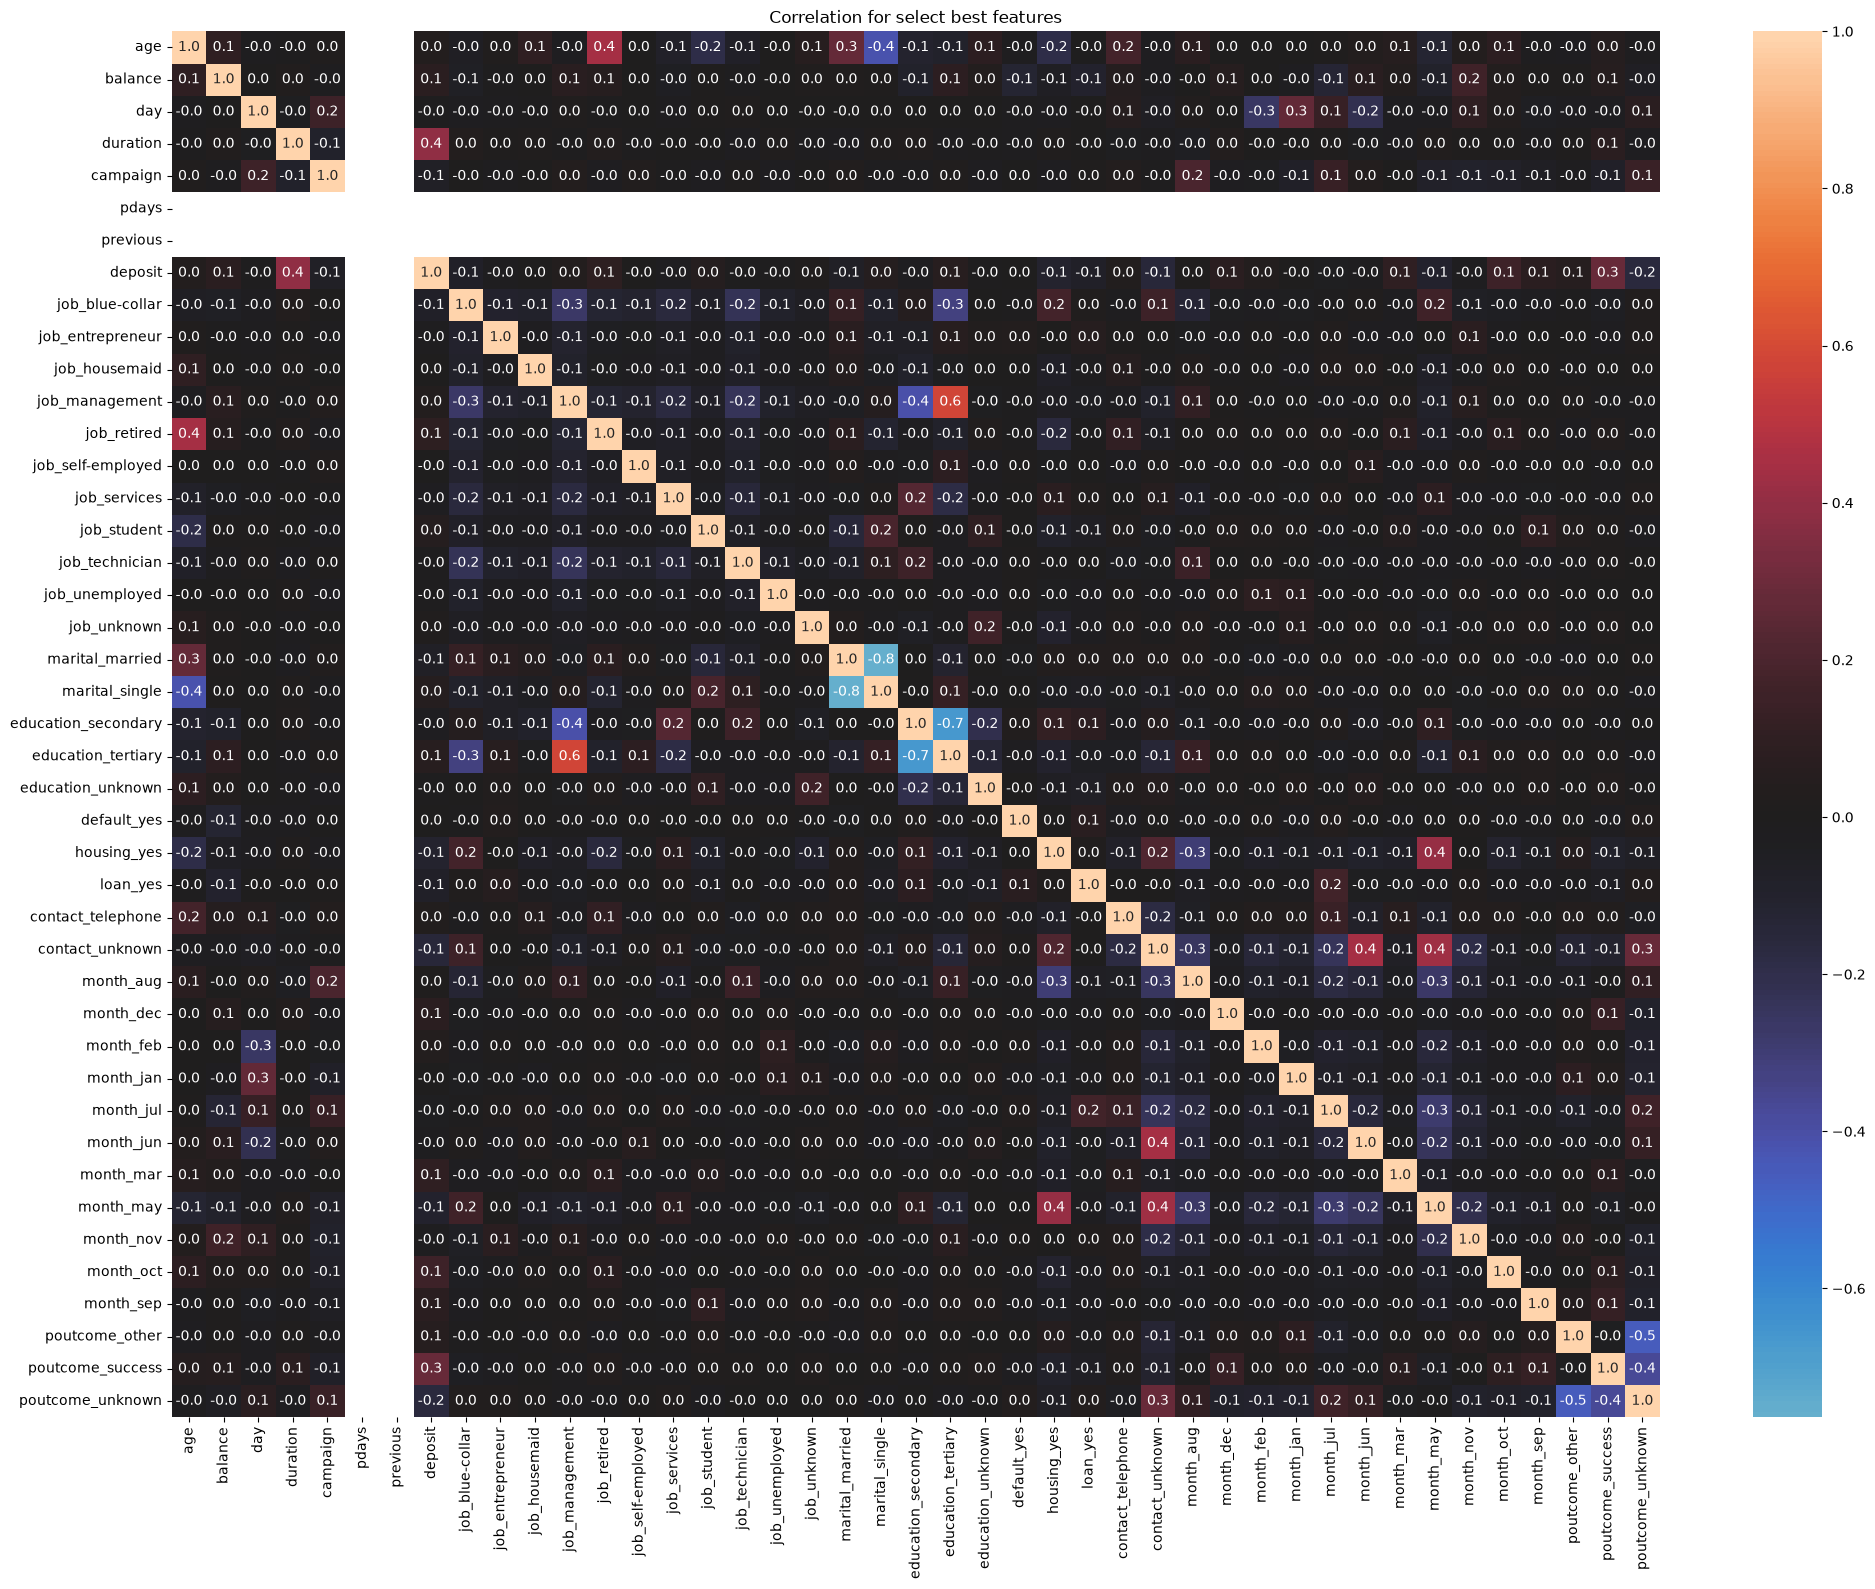

In [ ]:
encoded_corr=df_encoded.corr()
plt.figure(figsize=(24,18))
sns.heatmap(encoded_corr,annot=True,fmt=".1f",center=0)
plt.title("Correlation for select best features")
plt.show()

In [ ]:
print(encoded_corr['deposit'].sort_values(ascending=False).drop('deposit').head(12))

duration              0.393818
poutcome_success      0.283481
month_oct             0.145964
month_mar             0.102716
job_retired           0.086675
balance               0.073072
month_sep             0.071510
month_dec             0.069884
education_tertiary    0.056649
poutcome_other        0.051908
job_student           0.047809
marital_single        0.045815
Name: deposit, dtype: float64


In [ ]:
from sklearn.feature_selection import SelectKBest,f_classif

#Target value as y
y=df_encoded['deposit']

#Take a remaining features
df_num=df_encoded.drop('deposit',axis=1)


selector=SelectKBest(score_func=f_classif,k=12)
x=selector.fit_transform(df_num,y)

#Take a features from scores_
feature_score=selector.scores_

select_indices=selector.get_support(indices=True)
feature_names=df_num.columns[select_indices]

x=pd.DataFrame(x,columns=feature_names)
x.head()

,balance,duration,job_retired,housing_yes,loan_yes,contact_unknown,month_mar,month_may,month_oct,month_sep,poutcome_success,poutcome_unknown
0,0.655937,-0.878134,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,2.114953,-0.117521,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.303580,-0.306326,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.405175,-0.230804,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-0.784937,-0.085154,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


In [ ]:
feature_df=pd.DataFrame({'Feature:':df_num.columns,'Score':feature_score})
print(feature_df.sort_values(by='Score',ascending=False).head(12))

            Feature:       Score
3           duration  829.516124
40  poutcome_success  394.886884
41  poutcome_unknown  121.851168
37         month_oct   98.375106
27   contact_unknown   89.554061
24       housing_yes   50.070683
34         month_mar   48.186151
35         month_may   47.582574
11       job_retired   34.206091
1            balance   24.258618
38         month_sep   23.227662
25          loan_yes   22.583716


In [ ]:
best_features=x.columns
print(best_features)

Index(['balance', 'duration', 'job_retired', 'housing_yes', 'loan_yes',
       'contact_unknown', 'month_mar', 'month_may', 'month_oct', 'month_sep',
       'poutcome_success', 'poutcome_unknown'],
      dtype='object')


#5.2 Train Test Split

In [ ]:
#Train data
x=df_encoded[best_features]
y=df_encoded['deposit']
x.head()

,balance,duration,job_retired,housing_yes,loan_yes,contact_unknown,month_mar,month_may,month_oct,month_sep,poutcome_success,poutcome_unknown
0,0.655937,-0.878134,0,0,0,0,0,0,1,0,0,1
1,2.114953,-0.117521,0,1,1,0,0,1,0,0,0,0
2,0.303580,-0.306326,0,1,0,0,0,0,0,0,0,0
3,0.405175,-0.230804,0,1,1,1,0,0,0,0,0,1
4,-0.784937,-0.085154,0,1,0,1,0,1,0,0,0,1


In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,stratify=y,random_state=42)

In [ ]:
print(x_train.shape,x_test.shape)
print(y_train.shape,y_test.shape)

(3164, 12) (1357, 12)
(3164,) (1357,)


In [ ]:
#Install imbalanced-learn
!pip install -q imbalanced-learn

#SMOT method use
from imblearn.over_sampling import SMOTE
smote=SMOTE(random_state=42)
x_train,y_train=smote.fit_resample(x_train,y_train)


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


#6 Model Building

#Model 1
#Decision Tree Classifier

In [ ]:
from sklearn.tree import DecisionTreeClassifier
model_dtc=DecisionTreeClassifier(criterion='gini',max_depth=6,random_state=42)
model_dtc.fit(x_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [ ]:
# Make predictions
y_pred_dtc=model_dtc.predict(x_test)

In [ ]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test,y_pred_dtc))

[[969 232]
 [ 45 111]]


In [ ]:
y_train.value_counts()

deposit
0    2799
1    2799
Name: count, dtype: int64

In [ ]:
from sklearn.metrics import accuracy_score,classification_report
print(f"Accuracy Score:{accuracy_score(y_test,y_pred_dtc)}")
print("Classification Report\n",classification_report(y_test,y_pred_dtc))

Accuracy Score:0.7958732498157701
Classification Report
               precision    recall  f1-score   support

           0       0.96      0.81      0.87      1201
           1       0.32      0.71      0.44       156

    accuracy                           0.80      1357
   macro avg       0.64      0.76      0.66      1357
weighted avg       0.88      0.80      0.83      1357



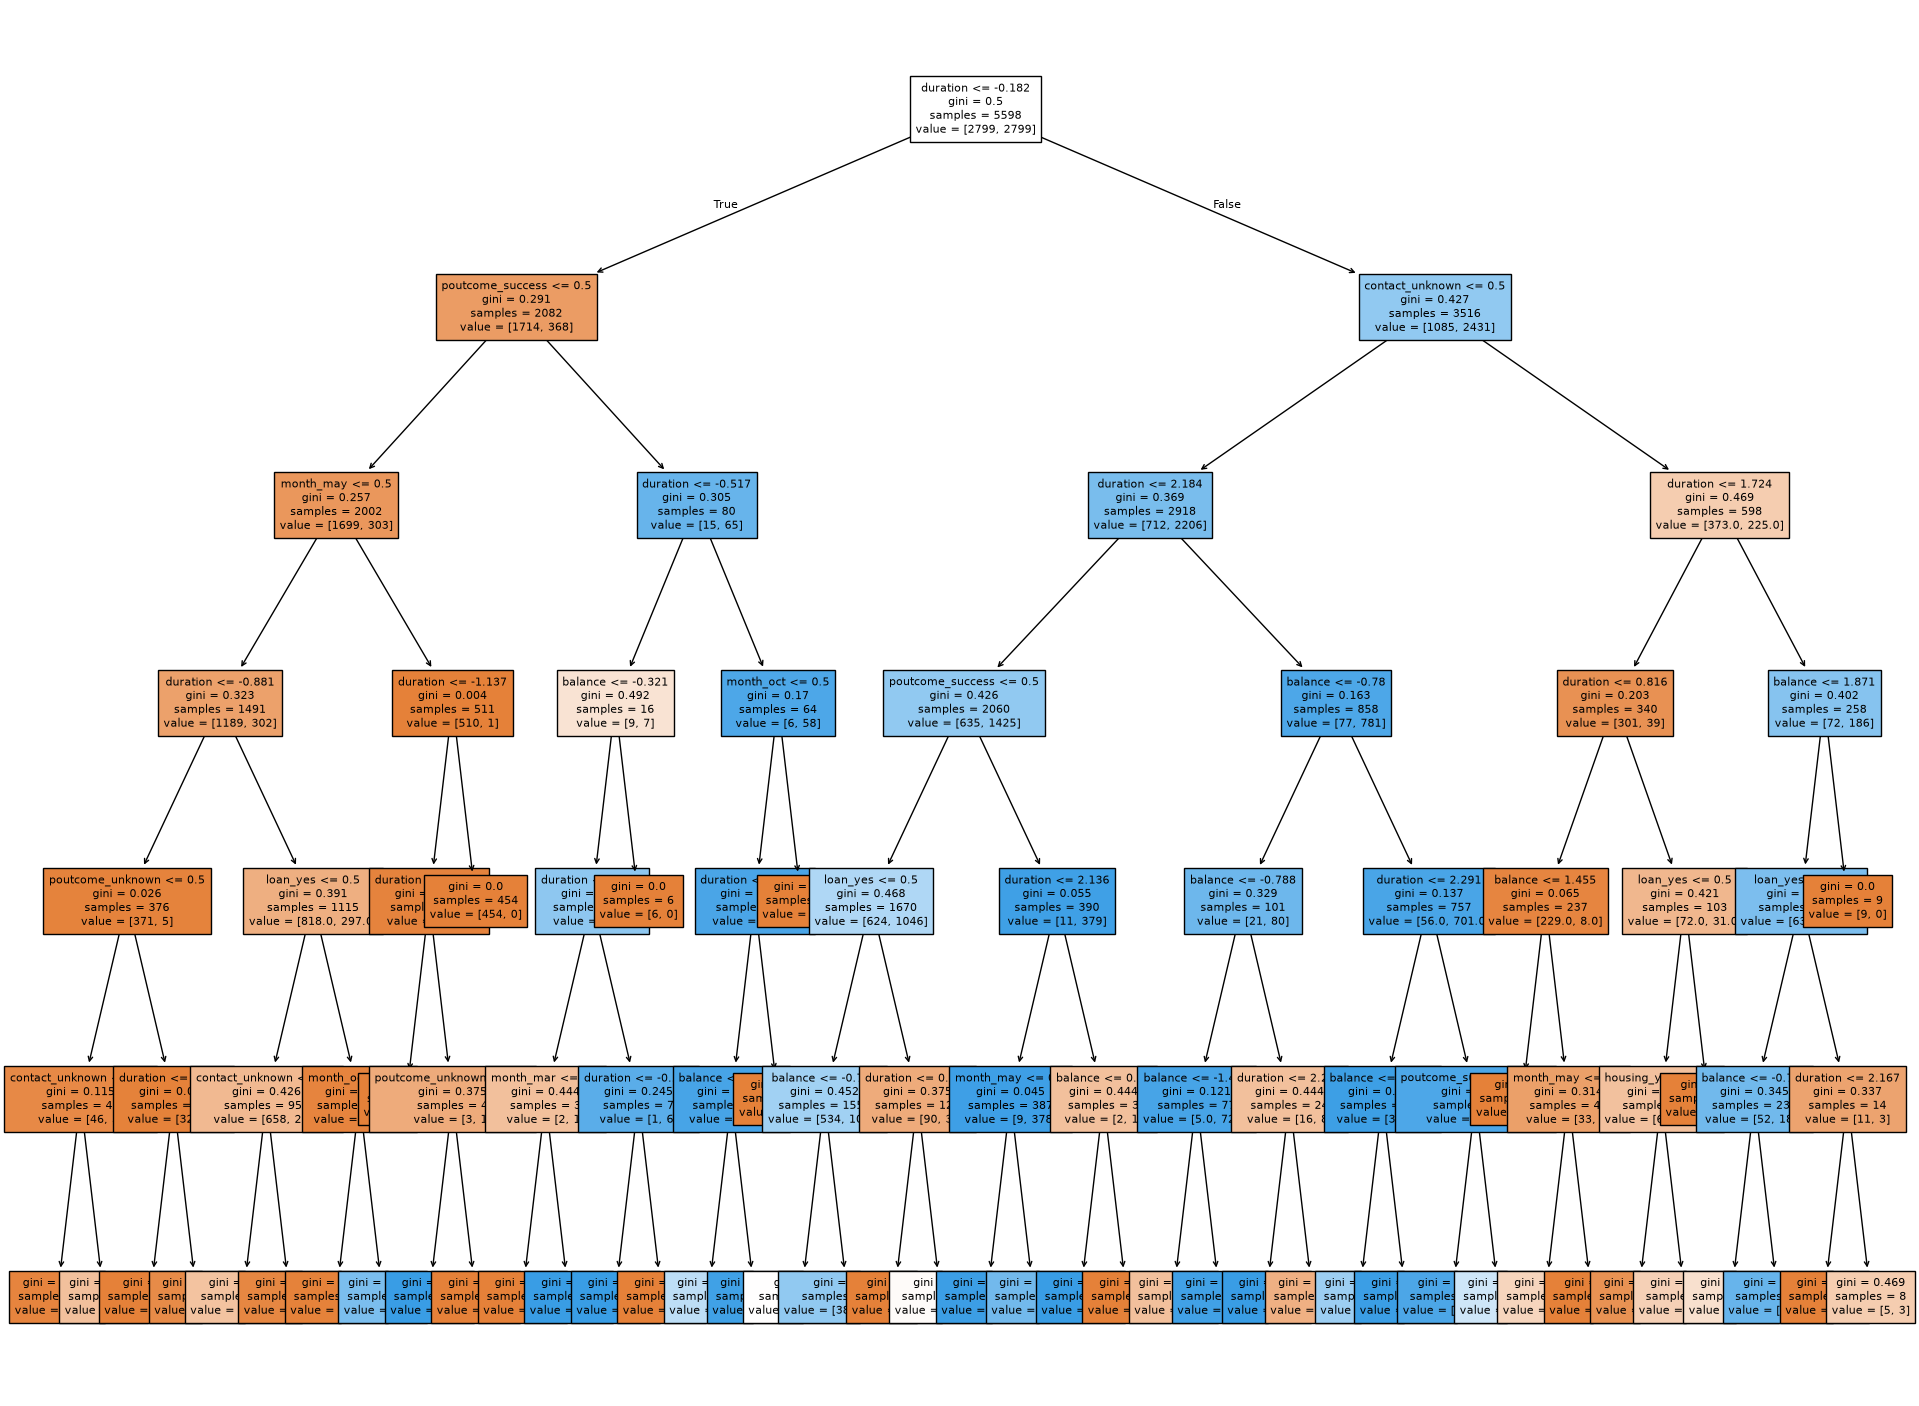

In [ ]:
from sklearn import tree
plt.figure(figsize=(24,18))
tree.plot_tree(model_dtc,
               feature_names=x.columns,
               filled=True,
               fontsize=8)
plt.show()

#Model 2
#KNeighbors Classifier

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
model_knn=KNeighborsClassifier(n_neighbors=5)
model_knn.fit(x_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [ ]:
y_pred_knn=model_knn.predict(x_test)

In [ ]:
print("Confusion Matrix\n",confusion_matrix(y_test,y_pred_knn))

Confusion Matrix
 [[974 227]
 [ 48 108]]


In [ ]:
print("Accuracy Score:",accuracy_score(y_test,y_pred_knn))
print("Classification Report:\n",classification_report(y_test,y_pred_knn))

Accuracy Score: 0.7973470891672808
Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.81      0.88      1201
           1       0.32      0.69      0.44       156

    accuracy                           0.80      1357
   macro avg       0.64      0.75      0.66      1357
weighted avg       0.88      0.80      0.83      1357



#Model 3
#Random Forest Classifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier
model_rf=RandomForestClassifier(n_estimators=100,random_state=42)
model_rf.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [ ]:
y_pred_rf=model_rf.predict(x_test)

In [ ]:
print("Confusion Matrix\n",confusion_matrix(y_test,y_pred_rf))

Confusion Matrix
 [[1035  166]
 [  75   81]]


In [ ]:
print("Accuracy score:",accuracy_score(y_test,y_pred_rf))
print("Classification Report:\n",classification_report(y_test,y_pred_rf))

Accuracy score: 0.8224023581429624
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.86      0.90      1201
           1       0.33      0.52      0.40       156

    accuracy                           0.82      1357
   macro avg       0.63      0.69      0.65      1357
weighted avg       0.86      0.82      0.84      1357



#Model 4
#Naive Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB
model_NB=GaussianNB()
model_NB.fit(x_train,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[2799.,2799.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.332e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['balance','duration','job_retired',...,'month_sep','poutcome_success', 'poutcome_unknown']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 12)","[[-0.02,-0.14, 0.04,..., 0.01, 0.01, 0.84], [ 0.19, 1.07, 0.05,..., 0.01, 0.16, 0.62]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 12)","[[0.99,0.82,0.04,...,0.01,0.01,0.13], [1.12,1.12,0.04,...,0.01,0.14,0.24]]"


In [ ]:
y_pred_NB=model_NB.predict(x_test)

In [ ]:
print("Confusion Matrix:\n",confusion_matrix(y_test,y_pred_NB))

Confusion Matrix:
 [[1095  106]
 [  72   84]]


In [ ]:
print("Accuracy Score:",accuracy_score(y_test,y_pred_NB))
print("Classification Report:\n",classification_report(y_test,y_pred_NB))

Accuracy Score: 0.868828297715549
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.91      0.92      1201
           1       0.44      0.54      0.49       156

    accuracy                           0.87      1357
   macro avg       0.69      0.73      0.71      1357
weighted avg       0.88      0.87      0.87      1357



#Model 5
#Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
model_lr=LogisticRegression(random_state=42)
model_lr.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solve

In [ ]:
y_pred_lr=model_lr.predict(x_test)

In [ ]:
print("Confusion Matrix:\n",confusion_matrix(y_test,y_pred_lr))


Confusion Matrix:
 [[979 222]
 [ 37 119]]


In [ ]:
print("Accuracy Score:",accuracy_score(y_test,y_pred_lr))
print("Classification Report:\n",classification_report(y_test,y_pred_lr))

Accuracy Score: 0.8091378039793663
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.82      0.88      1201
           1       0.35      0.76      0.48       156

    accuracy                           0.81      1357
   macro avg       0.66      0.79      0.68      1357
weighted avg       0.89      0.81      0.84      1357



#Model Evaluation

In [ ]:
# Restore the accuracy_score function and build the comparison table
from sklearn.metrics import accuracy_score

model_name = ['Decision Tree', 'KNN', 'Random Forest', 'Naive Bayes', 'Logistic Regression']
scores = [
    accuracy_score(y_test, y_pred_dtc),
    accuracy_score(y_test, y_pred_knn),
    accuracy_score(y_test, y_pred_rf),
    accuracy_score(y_test, y_pred_NB),
    accuracy_score(y_test, y_pred_lr)
]
table = pd.DataFrame({'Model': model_name, 'Accuracy Score': scores})
table.sort_values(by='Accuracy Score', ascending=False)

,Model,Accuracy Score
3,Naive Bayes,0.868828
2,Random Forest,0.822402
4,Logistic Regression,0.809138
1,KNN,0.797347
0,Decision Tree,0.795873


#7 Use hyperparameter tuning and stratifiedKFold

In [ ]:
from sklearn.model_selection import StratifiedKFold,GridSearchCV

In [ ]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

#Logistic Regression

In [ ]:
lr_param_grid={'C':[0.01,0.1,1,5],'penalty':['l2','l1']}
lr_grid=GridSearchCV(LogisticRegression(random_state=42),lr_param_grid,cv=cv,scoring='accuracy',verbose=1,n_jobs=-1)
lr_grid.fit(x_train,y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 0.1, ...], 'penalty': ['l2', 'l1']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digi

#Random Forest

In [ ]:
rf_param_grid={'n_estimators':[50,100,150],'max_depth':[3,5,7]}
rf_grid=GridSearchCV(RandomForestClassifier(random_state=42),rf_param_grid,cv=cv,scoring='accuracy',verbose=1,n_jobs=-1)
rf_grid.fit(x_train,y_train)

Fitting 5 folds for each of 9 candidates, totalling 45 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_s

#Decision Tree

In [ ]:
dt_param_grid={'max_depth':[3,5,7],'min_samples_split':[2,5,10]}
dt_grid=GridSearchCV(DecisionTreeClassifier(random_state=42),dt_param_grid,cv=cv,scoring='accuracy',verbose=1,n_jobs=-1)
dt_grid.fit(x_train,y_train)

Fitting 5 folds for each of 9 candidates, totalling 45 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid

#KNeighbors Classifier

In [ ]:
knn_param_grid={'n_neighbors':[3,5,7],'weights':['uniform','distance']}
knn_grid=GridSearchCV(KNeighborsClassifier(),knn_param_grid,cv=cv,scoring='accuracy',verbose=1,n_jobs=-1)
knn_grid.fit(x_train,y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': [3, 5, ...], 'weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_sea

#Naive Bayes

In [ ]:
nb_param_grid={'var_smoothing':[1e-9,1e-8,1e-7]}
nb_grid=GridSearchCV(GaussianNB(),nb_param_grid,cv=cv,scoring='accuracy',verbose=1,n_jobs=-1)
nb_grid.fit(x_train,y_train)

Fitting 5 folds for each of 3 candidates, totalling 15 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GaussianNB()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'var_smoothing': [1e-09, 1e-08, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a

#7.1 Best Parameter for all models

In [ ]:
# Extracting best estimators, best parameters, and best scores from the GridSearch results
best_models_data = {
    'Model': ['Logistic Regression', 'Random Forest', 'Decision Tree', 'KNN', 'Naive Bayes'],
    'Best Parameters': [
        str(lr_grid.best_params_),
        str(rf_grid.best_params_),
        str(dt_grid.best_params_),
        str(knn_grid.best_params_),
        str(nb_grid.best_params_)
    ]
}
best_param_models = pd.DataFrame(best_models_data)
best_param_models

,Model,Best Parameters
0,Logistic Regression,"{'C': 1, 'penalty': 'l2'}"
1,Random Forest,"{'max_depth': 7, 'n_estimators': 150}"
2,Decision Tree,"{'max_depth': 7, 'min_samples_split': 2}"
3,KNN,"{'n_neighbors': 7, 'weights': 'distance'}"
4,Naive Bayes,{'var_smoothing': 1e-09}


In [ ]:
#Train with best parameters for logistic regression
model_lr_best=LogisticRegression(C=1,penalty='l2',random_state=42)
model_lr_best.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because 

In [ ]:
y_pred_lr_best=model_lr.predict(x_test)
print("Accuracy Score:",accuracy_score(y_test,y_pred_lr_best))
print("Classification Report:\n",classification_report(y_test,y_pred_lr_best))

Accuracy Score: 0.8091378039793663
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.82      0.88      1201
           1       0.35      0.76      0.48       156

    accuracy                           0.81      1357
   macro avg       0.66      0.79      0.68      1357
weighted avg       0.89      0.81      0.84      1357



In [ ]:
#Train with best parameters knn
model_knn_best=KNeighborsClassifier(n_neighbors=3,weights='distance')
model_knn_best.fit(x_train,y_train)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [ ]:
y_pred_knn_best=model_knn_best.predict(x_test)
print("Accuracy Score:",accuracy_score(y_test,y_pred_knn_best))
print("Classification Report:\n",classification_report(y_test,y_pred_knn_best))

Accuracy Score: 0.8002947678703022
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.83      0.88      1201
           1       0.30      0.55      0.39       156

    accuracy                           0.80      1357
   macro avg       0.62      0.69      0.63      1357
weighted avg       0.86      0.80      0.82      1357



In [ ]:
#Train with best parameters randomforest
model_rf_best=RandomForestClassifier(max_depth=5,n_estimators=100,random_state=42)
model_rf_best.fit(x_train,y_train)
y_pred_rf_best=model_rf_best.predict(x_test)
print("Accuracy Score:",accuracy_score(y_test,y_pred_rf_best))
print("Classification Report:\n",classification_report(y_test,y_pred_rf_best))

Accuracy Score: 0.7855563743551953
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.78      0.87      1201
           1       0.33      0.81      0.47       156

    accuracy                           0.79      1357
   macro avg       0.65      0.80      0.67      1357
weighted avg       0.90      0.79      0.82      1357



In [ ]:
#Train with best parameters Decision Tree
model_dt_best=DecisionTreeClassifier(max_depth=5,min_samples_split=2,random_state=42)
model_dt_best.fit(x_train,y_train)
y_pred_dt_best=model_dt_best.predict(x_test)
print("Accuracy Score:",accuracy_score(y_test,y_pred_dt_best))
print("Classification Report:\n",classification_report(y_test,y_pred_dt_best))

Accuracy Score: 0.765659543109801
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.76      0.85      1201
           1       0.30      0.78      0.43       156

    accuracy                           0.77      1357
   macro avg       0.63      0.77      0.64      1357
weighted avg       0.89      0.77      0.80      1357



In [ ]:
#Train with best parameters Naive Bayes
model_nb_best=GaussianNB(var_smoothing=1e-09)
model_nb_best.fit(x_train,y_train)
y_pred_nb_best=model_nb_best.predict(x_test)
print("Accuracy Score:",accuracy_score(y_test,y_pred_nb_best))
print("Classification Report:\n",classification_report(y_test,y_pred_nb_best))

Accuracy Score: 0.868828297715549
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.91      0.92      1201
           1       0.44      0.54      0.49       156

    accuracy                           0.87      1357
   macro avg       0.69      0.73      0.71      1357
weighted avg       0.88      0.87      0.87      1357



In [ ]:
result=[]
for name,model in zip(['Logistic Regression','KNN','Random Forest','Decision Tree','Naive Bayes'],
                     [model_lr_best,model_knn_best,model_rf_best,model_dt_best,model_nb_best]):
  y_pred=model.predict(x_test)
  result.append([name,accuracy_score(y_test,y_pred)])
result=pd.DataFrame(result,columns=['Model','Accuracy Score'])
best_results=result.sort_values(by='Accuracy Score',ascending=False)
print("After Hyperparameter tuning the best models are:")
best_results



After Hyperparameter tuning the best models are:


,Model,Accuracy Score
4,Naive Bayes,0.868828
0,Logistic Regression,0.809138
1,KNN,0.800295
2,Random Forest,0.785556
3,Decision Tree,0.765660


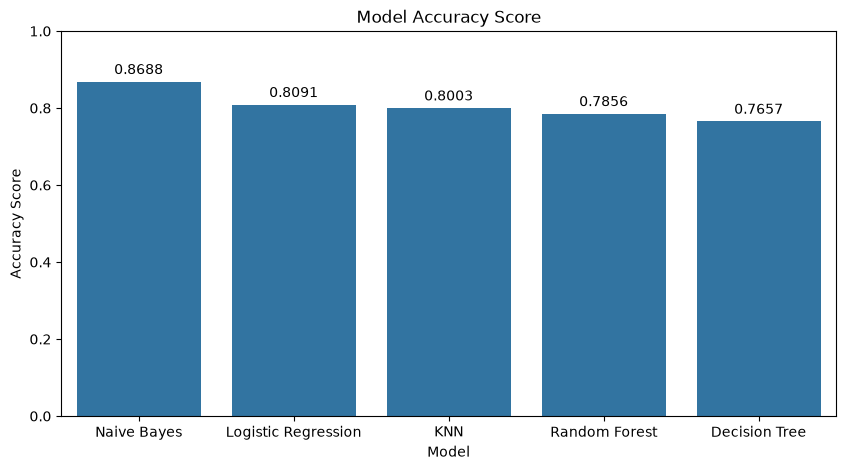

In [ ]:
plt.figure(figsize=(10,5))
ax = sns.barplot(data=best_results, x='Model', y='Accuracy Score')
ax.bar_label(ax.containers[0], fmt='%.4f', padding=3)
plt.title("Model Accuracy Score")
plt.xlabel("Model")
plt.ylabel("Accuracy Score")
plt.ylim(0, 1.0)
plt.show()

#Best Model Name and metrices

----Best Model:----- Naive Bayes ****

Accuracy Score: 0.868828297715549

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.91      0.92      1201
           1       0.44      0.54      0.49       156

    accuracy                           0.87      1357
   macro avg       0.69      0.73      0.71      1357
weighted avg       0.88      0.87      0.87      1357



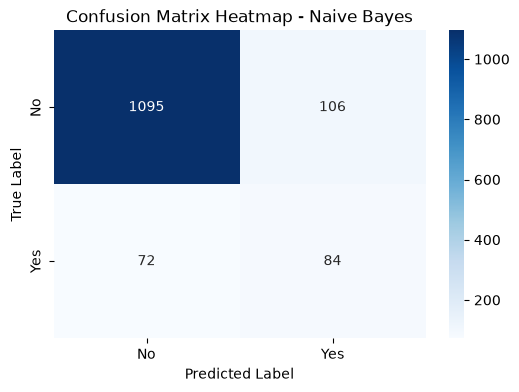

In [ ]:
best_model_name = 'Naive Bayes'
best_model = model_nb_best
y_pred_best = y_pred_nb_best

print(f"----Best Model:----- {best_model_name} ****\n")
print("Accuracy Score:", accuracy_score(y_test, y_pred_best))
print("\nClassification Report:\n", classification_report(y_test, y_pred_best))

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_best)

# Plot confusion matrix heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.title(f'Confusion Matrix Heatmap - {best_model_name}')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

#Conclusion

This project developed a machine learning-based system to predict whether bank customers will subscribe to a term deposit using demographic, financial and previous campaign data. Data preprocessing, exploratory data analysis, feature selection and SMOTE techniques were performed to improve data quality and handle class imbalance. Five machine learning algorithms were implemented and evaluated using accuracy, precision, recall and F1-score. Hyperparameter tuning was performed to identify the best-performing model. Among the evaluated algorithms, Naive Bayes achieved the highest accuracy of **86.88%**. The proposed system can help banks identify potential customers, reduce unnecessary marketing efforts and improve the effectiveness of future telemarketing campaigns.